# WAPLA 2026 — EDA: Structural Diagnosis of Rejected AI-Generated Questions

**Dataset:** [`aiboxlab/ai-generated-questions-quality`](https://huggingface.co/datasets/aiboxlab/ai-generated-questions-quality) (Hugging Face) — 239 AI-generated items that were **rejected**. The rejection reason is not provided as a label; this notebook reverse-engineers it via **structural metadata analysis**, not model training.

**Method grounding.** Every analysis below is anchored to a specific rule in this project's `constitution.md` (the AIG system's immutable rule set), so findings map directly onto engineering fixes for the Generator/Judge pipeline described in `spec.md`:

| Analysis | Constitution rule(s) | What it operationalizes |
|---|---|---|
| Verbosity Bias (option length) | **R16** (item-writing-flaw taxonomy: conspicuously-correct-choice, answer-length cueing — Haladyna, Downing & Rodriguez 2002), **R22** (verbosity bias, written for LLM-judge scoring but the same generator-side failure mode: the correct option is often paraphrased from source text and ends up systematically longer/shorter than invented distractors) | Is `correct_option` a length outlier relative to its distractors? |
| Position Bias (`correct_option` distribution) | **R21** (position bias), **R16** citing Downing (Handbook of Test Development, ch. 12, Rule 22: *"keep choices independent; choices should not be overlapping"*) and the Guia BNI-Enade's ban on absolute-cueing / structurally telegraphed answers | Is the generator defaulting the correct answer to a fixed slot (e.g. `A`) far more often than the 1-in-5 chance rate? |
| Bloom's Taxonomy verb mismatch | **R6–R11** (strict Bloom alignment), specifically **R9** (MCQ format is restricted to Remember/Understand/Apply/Analyze — Evaluate/Create must **not** be assessed via MCQ) and **R10** (fixed, level-specific verb-bank contract, never free-form) | Does the verb actually used in `stem` match the *declared* `taxonomy_level`? Is the item even in a legal format for that level? |
| Reporting standard | **R34** (variance-decomposed/resampling uncertainty, not a single point estimate) and **spec.md §6.5** ("Ten Simple Rules for Better Figures" — Rougier, Droettboom & Bourne, 2014) | Every headline statistic below carries a bootstrap confidence interval; every figure uses an appropriate colormap, un-truncated axes, and a self-contained caption. |

No model is trained in this notebook. All findings are descriptive/statistical and feed the WAPLA Technical Report.


## 0. Setup, Reproducibility & Output Directory

Global seeds are fixed per standard reproducibility practice. Any resampling-based
uncertainty estimate below (per **R34**) draws from a single seeded `numpy`
generator so the notebook is deterministic end-to-end.

In [1]:
import os
import re
import random
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Global reproducibility seed (R34: deterministic resampling/uncertainty) ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

# --- Output directory for the Technical Report ---
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

# --- Plot style: per spec.md §6.5 ("Ten Simple Rules for Better Figures") ---
# sequential palette for ordered magnitudes, qualitative for unordered
# categories, no 3D/pie charts, no truncated axes, self-contained titles.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 11

QUALITATIVE_PALETTE = sns.color_palette("Set2")
SEQUENTIAL_CMAP = "Blues"
DIVERGING_CMAP = "RdBu_r"

print(f"Seed set to {SEED}. Plots will be saved to: {OUTPUT_DIR.resolve()}")


Seed set to 42. Plots will be saved to: C:\Users\vflc2\Desktop\meu_projeto_mestrado\output


## 1. Data Loading

The dataset is loaded via the Hugging Face `datasets` library. **Note:** the
canonical `load_dataset(...)` call is written exactly as specified, but this
dataset does *not* expose a `train` split — it exposes a single split named
`data` (verified by inspection). The loader below is written defensively so it
still works if the maintainers rename the split to `train` in a future
version, rather than hard-failing on a `KeyError`.

In [2]:
from datasets import load_dataset

ds = load_dataset("aiboxlab/ai-generated-questions-quality")

# Defensive split resolution: prefer 'train' if present (as specified), else
# fall back to whatever single split the dataset actually exposes.
if "train" in ds:
    split_name = "train"
else:
    available = list(ds.keys())
    split_name = available[0]
    print(
        f"NOTE: no 'train' split found. Available split(s): {available}. "
        f"Falling back to '{split_name}'."
    )

df = ds[split_name].to_pandas()

print(f"Loaded split '{split_name}': {df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)


C:\Users\vflc2\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NOTE: no 'train' split found. Available split(s): ['data']. Falling back to 'data'.
Loaded split 'data': 239 rows x 18 columns


,question_id,discipline,question_type,taxonomy_level,base_text,stem,statement_i,statement_ii,statement_iii,statement_iv,assertion_i,assertion_ii,option_a,option_b,option_c,option_d,option_e,correct_option
0,1,História da Filosofia Medieval,Afirmação Incompleta,Avaliar,"Em um curso de História da Filosofia Medieval,...","Ao revisar o trabalho desse terceiro grupo, um...",NaN,NaN,NaN,NaN,NaN,NaN,reexamina os escritos utilizados em contextos ...,privilegia os textos bíblicos que suscitam mai...,escolhe os escritos que apresentam linguagem m...,hierarquiza os textos bíblicos a partir da fre...,define como centrais os escritos associados a ...,A
1,2,Educação de Jovens e Adultos,Afirmação Incompleta,Avaliar,A Educação de Jovens e Adultos (EJA) atende su...,"Nesse contexto, uma ação pedagógica adequada à...",NaN,NaN,NaN,NaN,NaN,NaN,possuem trajetória homogênea e aprendem melhor...,apresentam necessidades específicas de aprendi...,têm como principal característica a impossibil...,devem ser tratados prioritariamente como um gr...,necessitam apenas de conteúdos básicos e repet...,B
2,3,ENSINO E APRENDIZAGEM DAS CIÊNCIAS NATURAIS,Afirmação Incompleta,Analisar,Em uma atividade investigativa sobre a fauna d...,Ao sistematizar os dados coletados sobre os an...,NaN,NaN,NaN,NaN,NaN,NaN,destacar os diferentes hábitos alimentares de ...,"comparar o tamanho corporal de insetos, peixes...","classificar insetos, peixes, anfíbios, aves e ...","agrupar insetos, peixes, anfíbios, aves e mamí...","separar insetos, peixes, anfíbios, aves e mamí...",A


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 239 entries, 0 to 238
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   question_id     239 non-null    int64
 1   discipline      239 non-null    str  
 2   question_type   239 non-null    str  
 3   taxonomy_level  239 non-null    str  
 4   base_text       239 non-null    str  
 5   stem            239 non-null    str  
 6   statement_i     30 non-null     str  
 7   statement_ii    30 non-null     str  
 8   statement_iii   30 non-null     str  
 9   statement_iv    30 non-null     str  
 10  assertion_i     16 non-null     str  
 11  assertion_ii    16 non-null     str  
 12  option_a        239 non-null    str  
 13  option_b        239 non-null    str  
 14  option_c        239 non-null    str  
 15  option_d        239 non-null    str  
 16  option_e        239 non-null    str  
 17  correct_option  239 non-null    str  
dtypes: int64(1), str(17)
memory usage: 424.8 

## 1.1 Data Quality Overview (Structural Metadata)

Before diagnosing latent flaws, we characterize the raw structural metadata:
missingness patterns, category distributions, and a check for **case-duplicated
categories** (a common structural artifact — e.g. `"Arte Contemporânea"` vs.
`"ARTE CONTEMPORÂNEA"` silently fragmenting what should be one `discipline`
bucket).

In [4]:
null_counts = df.isna().sum()
print("Null counts per column:")
print(null_counts[null_counts > 0])

print("\nquestion_type value counts:")
print(df["question_type"].value_counts())

print("\ntaxonomy_level value counts:")
print(df["taxonomy_level"].value_counts())


Null counts per column:
statement_i      209
statement_ii     209
statement_iii    209
statement_iv     209
assertion_i      223
assertion_ii     223
dtype: int64

question_type value counts:
question_type
Afirmação Incompleta         113
Múltipla Escolha Simples      80
Múltipla Escolha Complexa     30
Asserção-Razão                16
Name: count, dtype: int64

taxonomy_level value counts:
taxonomy_level
Avaliar        166
Analisar        45
Aplicar         19
Criar            6
Compreender      3
Name: count, dtype: int64


In [5]:
# --- Case-duplication check on 'discipline' (structural metadata hygiene) ---
raw_unique = df["discipline"].nunique()
normalized = df["discipline"].str.strip().str.lower()
norm_unique = normalized.nunique()

print(f"Unique 'discipline' values (raw):        {raw_unique}")
print(f"Unique 'discipline' values (normalized): {norm_unique}")
print(f"=> {raw_unique - norm_unique} raw categories are pure casing duplicates "
      f"of another category.")

dup_report = (
    df.assign(discipline_norm=normalized)
    .groupby("discipline_norm")["discipline"]
    .agg(lambda s: sorted(s.unique()))
)
dup_report = dup_report[dup_report.apply(len) > 1]
print("\nCase-duplicated discipline labels:")
for norm_key, variants in dup_report.items():
    print(f"  {variants}")


Unique 'discipline' values (raw):        26
Unique 'discipline' values (normalized): 22
=> 4 raw categories are pure casing duplicates of another category.

Case-duplicated discipline labels:
  ['ARTE CONTEMPORÂNEA', 'Arte Contemporânea']
  ['Cálculo Diferencial e Integral III', 'Cálculo diferencial e integral III']
  ['EDUCAÇÃO DE JOVENS E ADULTOS', 'Educação de Jovens e Adultos']
  ['Morfossintaxe da Língua Inglesa', 'Morfossintaxe da língua inglesa']


C:\Users\vflc2\AppData\Local\Temp\ipykernel_12324\519770403.py:4: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.countplot(
C:\Users\vflc2\AppData\Local\Temp\ipykernel_12324\519770403.py:13: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.
  sns.countplot(


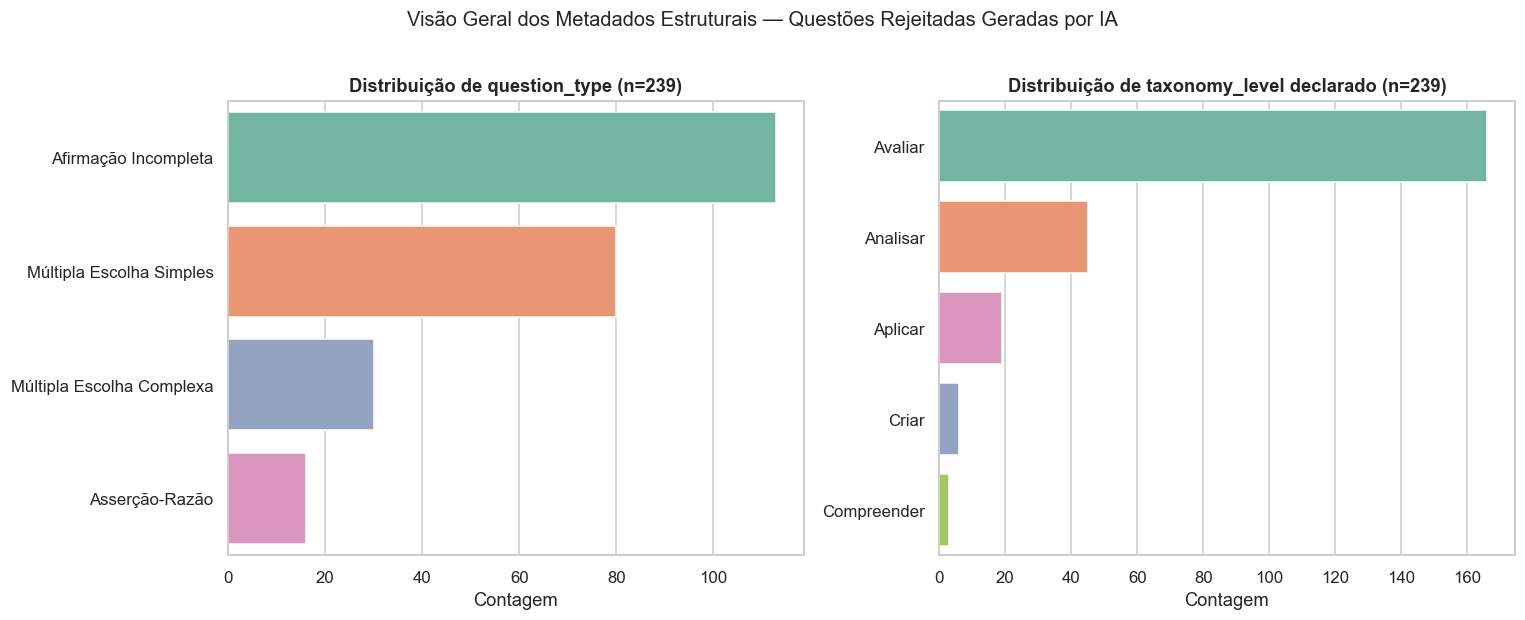

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

order_qt = df["question_type"].value_counts().index
sns.countplot(
    data=df, y="question_type", order=order_qt,
    hue="question_type", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[0],
)
axes[0].set_title("Distribuição de question_type (n=239)")
axes[0].set_xlabel("Contagem")
axes[0].set_ylabel("")

order_tax = df["taxonomy_level"].value_counts().index
sns.countplot(
    data=df, y="taxonomy_level", order=order_tax,
    hue="taxonomy_level", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[1],
)
axes[1].set_title("Distribuição de taxonomy_level declarado (n=239)")
axes[1].set_xlabel("Contagem")
axes[1].set_ylabel("")

fig.suptitle("Visão Geral dos Metadados Estruturais — Questões Rejeitadas Geradas por IA", y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_overview_distributions.png", bbox_inches="tight")
plt.show()


## 2. Verbosity Bias — Is `correct_option` a Length Outlier?

Per **R22** and the answer-length cueing flaw named in **R16** (Haladyna,
Downing & Rodriguez, 2002), a generator that paraphrases the correct answer
from source text while inventing distractors from scratch tends to leave the
correct option **systematically longer** (or, less commonly, shorter) than
its distractors — a structural giveaway a test-taker can exploit without any
domain knowledge.

For every item we compare the length of `correct_option` against the mean
length of its (up to 4) distractor options.

In [7]:
OPTION_COLS = ["option_a", "option_b", "option_c", "option_d", "option_e"]
LETTER_TO_COL = {"A": "option_a", "B": "option_b", "C": "option_c",
                  "D": "option_d", "E": "option_e"}

def option_lengths(row, unit="words"):
    lengths = {}
    for col in OPTION_COLS:
        text = row[col]
        if pd.isna(text):
            continue
        text = str(text)
        lengths[col] = len(text.split()) if unit == "words" else len(text)
    return lengths

def verbosity_stats(row, unit="words"):
    lengths = option_lengths(row, unit=unit)
    correct_col = LETTER_TO_COL.get(str(row["correct_option"]).strip().upper())
    if correct_col is None or correct_col not in lengths:
        return pd.Series({"correct_len": np.nan, "distractor_mean_len": np.nan,
                           "len_diff": np.nan, "is_longest": np.nan,
                           "is_shortest": np.nan, "n_options": len(lengths)})
    correct_len = lengths[correct_col]
    distractor_lens = [v for k, v in lengths.items() if k != correct_col]
    distractor_mean = np.mean(distractor_lens) if distractor_lens else np.nan
    all_lens = list(lengths.values())
    return pd.Series({
        "correct_len": correct_len,
        "distractor_mean_len": distractor_mean,
        "len_diff": correct_len - distractor_mean,
        "is_longest": correct_len == max(all_lens),
        "is_shortest": correct_len == min(all_lens),
        "n_options": len(lengths),
    })

verb_word = df.apply(lambda r: verbosity_stats(r, unit="words"), axis=1)
verb_char = df.apply(lambda r: verbosity_stats(r, unit="chars"), axis=1).add_suffix("_char")

df = pd.concat([df, verb_word, verb_char], axis=1)

print(df[["n_options", "correct_len", "distractor_mean_len", "len_diff"]].describe())


       n_options  correct_len  distractor_mean_len    len_diff
count      239.0   239.000000           239.000000  239.000000
mean         5.0    20.071130            17.784519    2.286611
std          0.0    13.374972            10.820422    4.555156
min          5.0     1.000000             1.000000   -9.750000
25%          5.0     9.500000             9.875000   -0.375000
50%          5.0    18.000000            16.250000    1.500000
75%          5.0    28.500000            25.750000    3.750000
max          5.0    79.000000            54.750000   37.500000


In [8]:
def bootstrap_ci(values, statistic=np.mean, n_boot=10_000, ci=95, rng=RNG):
    values = np.asarray(values)
    values = values[~np.isnan(values)]
    boot_stats = np.empty(n_boot)
    n = len(values)
    for i in range(n_boot):
        sample = values[rng.integers(0, n, size=n)]
        boot_stats[i] = statistic(sample)
    lower = np.percentile(boot_stats, (100 - ci) / 2)
    upper = np.percentile(boot_stats, 100 - (100 - ci) / 2)
    return statistic(values), lower, upper

mean_diff, ci_lo, ci_hi = bootstrap_ci(df["len_diff"].values)
wilcoxon_stat, wilcoxon_p = stats.wilcoxon(df["len_diff"].dropna())

pct_longest = df["is_longest"].mean() * 100
pct_shortest = df["is_shortest"].mean() * 100

print(f"Mean (correct_len - distractor_mean_len), in words: {mean_diff:+.2f}")
print(f"  95% bootstrap CI (n_boot=10,000, seed={SEED}): [{ci_lo:+.2f}, {ci_hi:+.2f}]")
print(f"Wilcoxon signed-rank test vs. 0: statistic={wilcoxon_stat:.1f}, p={wilcoxon_p:.4g}")
print(f"\ncorrect_option is the LONGEST of its options in  {pct_longest:.1f}% of items "
      f"(chance level for 5 options = 20.0%)")
print(f"correct_option is the SHORTEST of its options in {pct_shortest:.1f}% of items "
      f"(chance level for 5 options = 20.0%)")

# Explicit variance comparison (word- and character-based) as requested:
# does the correct option come from a systematically different length
# distribution than distractors, not just a different mean?
var_table = pd.DataFrame({
    "variance_words": [df["correct_len"].var(), df["distractor_mean_len"].var()],
    "variance_chars": [df["correct_len_char"].var(), df["distractor_mean_len_char"].var()],
}, index=["correct_option", "distractor_mean"])
print("\nOption-length variance (correct vs. distractor mean), words & characters:")
print(var_table.round(2))
levene_stat, levene_p = stats.levene(
    df["correct_len"].dropna(), df["distractor_mean_len"].dropna()
)
print(f"\nLevene's test for equal variances (correct vs. distractor mean length): "
      f"stat={levene_stat:.2f}, p={levene_p:.4g}")


Mean (correct_len - distractor_mean_len), in words: +2.29
  95% bootstrap CI (n_boot=10,000, seed=42): [+1.74, +2.88]
Wilcoxon signed-rank test vs. 0: statistic=4571.5, p=3.637e-16

correct_option is the LONGEST of its options in  49.8% of items (chance level for 5 options = 20.0%)
correct_option is the SHORTEST of its options in 26.4% of items (chance level for 5 options = 20.0%)

Option-length variance (correct vs. distractor mean), words & characters:
                 variance_words  variance_chars
correct_option           178.89         8497.01
distractor_mean          117.08         5531.49

Levene's test for equal variances (correct vs. distractor mean length): stat=7.02, p=0.00834


C:\Users\vflc2\AppData\Local\Temp\ipykernel_12324\1854806159.py:7: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(


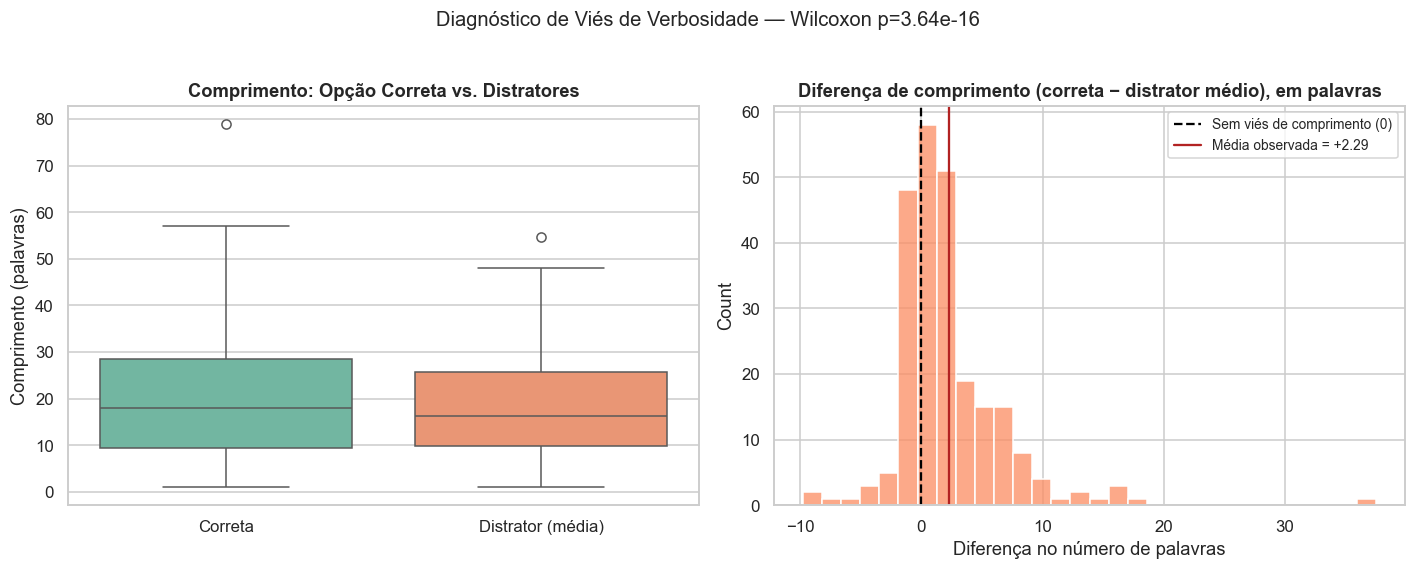

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_df = pd.DataFrame({
    "Papel da opção": ["Correta"] * len(df) + ["Distrator (média)"] * len(df),
    "Comprimento (palavras)": pd.concat([df["correct_len"], df["distractor_mean_len"]]).values,
})
sns.boxplot(
    data=plot_df, x="Papel da opção", y="Comprimento (palavras)",
    hue="Papel da opção", palette=QUALITATIVE_PALETTE, legend=False, ax=axes[0],
)
axes[0].set_title("Comprimento: Opção Correta vs. Distratores")
axes[0].set_xlabel("")

sns.histplot(df["len_diff"].dropna(), bins=30, color=QUALITATIVE_PALETTE[1], ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1.5, label="Sem viés de comprimento (0)")
axes[1].axvline(mean_diff, color="firebrick", linestyle="-", linewidth=1.5,
                 label=f"Média observada = {mean_diff:+.2f}")
axes[1].set_title("Diferença de comprimento (correta − distrator médio), em palavras")
axes[1].set_xlabel("Diferença no número de palavras")
axes[1].legend(loc="upper right", fontsize=9)

fig.suptitle(
    f"Diagnóstico de Viés de Verbosidade — Wilcoxon p={wilcoxon_p:.3g}", y=1.03
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_verbosity_bias.png", bbox_inches="tight")
plt.show()


C:\Users\vflc2\AppData\Local\Temp\ipykernel_12324\1767305667.py:3: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.boxplot(


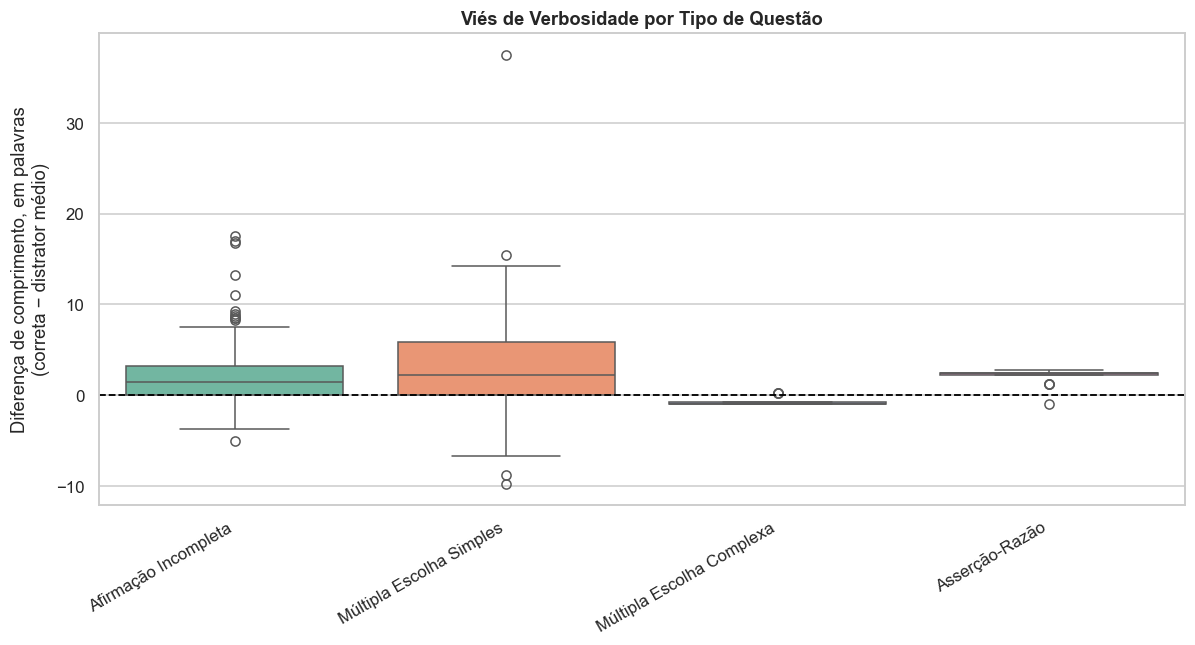

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
order_qt = df["question_type"].value_counts().index
sns.boxplot(
    data=df, x="question_type", y="len_diff", order=order_qt,
    hue="question_type", palette=QUALITATIVE_PALETTE, legend=False, ax=ax,
)
ax.axhline(0, color="black", linestyle="--", linewidth=1.2)
ax.set_title("Viés de Verbosidade por Tipo de Questão")
ax.set_xlabel("")
ax.set_ylabel("Diferença de comprimento, em palavras\n(correta − distrator médio)")
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02b_verbosity_bias_by_question_type.png", bbox_inches="tight")
plt.show()


## 3. Position Bias — Distribution of `correct_option`

Per **R21** and the independence/non-cueing rule in **R16** (Downing,
*Handbook of Test Development*, ch. 12, Rule 22 — *"keep choices
independent"*), a well-formed item bank should place the correct answer
roughly uniformly across positions A–E (~20% each). A generator that
defaults to a fixed slot leaks a trivial, content-free heuristic to any
test-taker ("always guess A").

In [11]:
pos_counts = df["correct_option"].value_counts().reindex(list("ABCDE")).fillna(0).astype(int)
pos_props = pos_counts / pos_counts.sum()

print("correct_option distribution:")
print(pd.DataFrame({"count": pos_counts, "proportion": pos_props.round(4)}))

chi2, chi2_p = stats.chisquare(pos_counts.values)
print(f"\nChi-square goodness-of-fit vs. uniform (expected {pos_counts.sum()/5:.1f} each): "
      f"chi2={chi2:.2f}, p={chi2_p:.4g}")

p_a, p_a_lo, p_a_hi = bootstrap_ci((df["correct_option"] == "A").astype(float).values)
print(f"\nP(correct_option == 'A') = {p_a:.3f}  "
      f"95% bootstrap CI [{p_a_lo:.3f}, {p_a_hi:.3f}]  (chance level = 0.200)")


correct_option distribution:
                count  proportion
correct_option                   
A                 193      0.8075
B                  16      0.0669
C                  24      0.1004
D                   4      0.0167
E                   2      0.0084

Chi-square goodness-of-fit vs. uniform (expected 47.8 each): chi2=558.09, p=1.816e-119

P(correct_option == 'A') = 0.808  95% bootstrap CI [0.757, 0.858]  (chance level = 0.200)


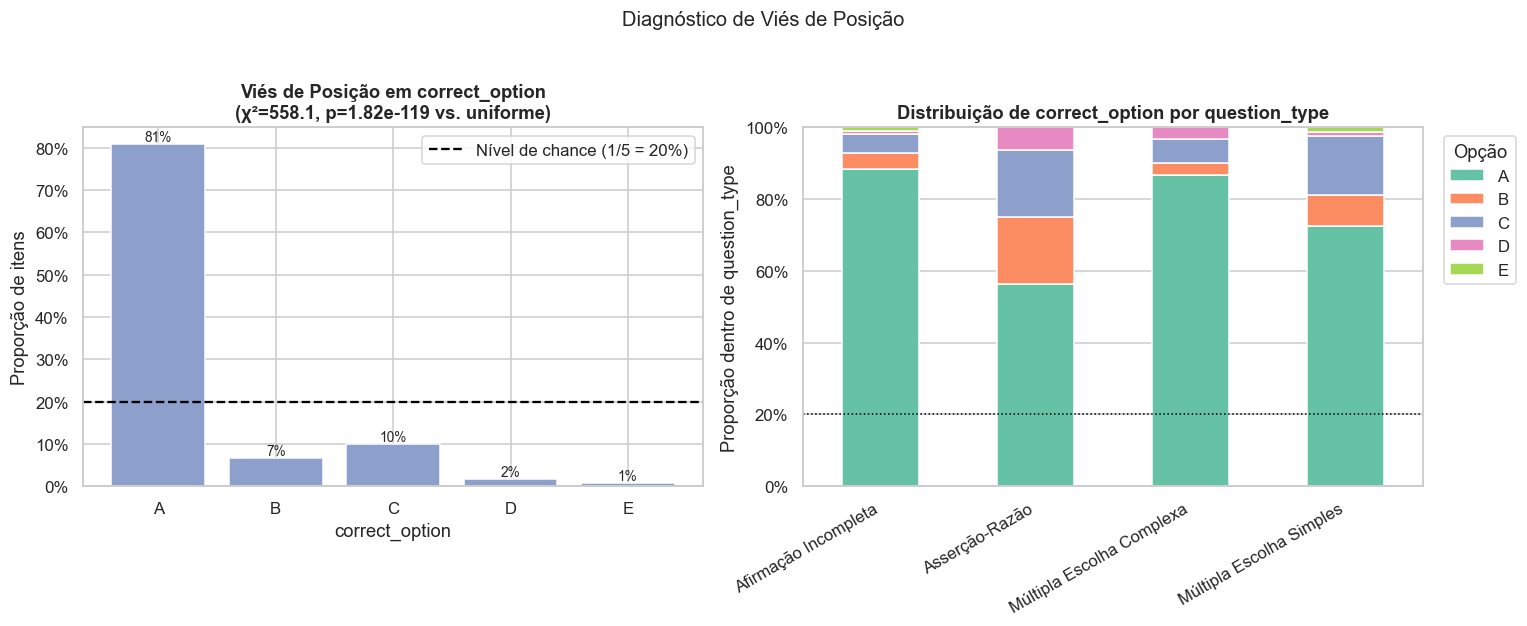

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

bars = axes[0].bar(pos_props.index, pos_props.values, color=QUALITATIVE_PALETTE[2])
axes[0].axhline(0.20, color="black", linestyle="--", linewidth=1.5,
                 label="Nível de chance (1/5 = 20%)")
axes[0].set_title(f"Viés de Posição em correct_option\n"
                    f"(χ²={chi2:.1f}, p={chi2_p:.2e} vs. uniforme)")
axes[0].set_ylabel("Proporção de itens")
axes[0].set_xlabel("correct_option")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
axes[0].legend()
for bar, prop in zip(bars, pos_props.values):
    axes[0].annotate(f"{prop:.0%}", (bar.get_x() + bar.get_width() / 2, prop),
                       ha="center", va="bottom", fontsize=9)

ct = pd.crosstab(df["question_type"], df["correct_option"], normalize="index")
ct = ct.reindex(columns=list("ABCDE"), fill_value=0)
ct.plot(kind="bar", stacked=True, ax=axes[1], color=sns.color_palette("Set2", 5))
axes[1].axhline(0.20, color="black", linestyle=":", linewidth=1)
axes[1].set_title("Distribuição de correct_option por question_type")
axes[1].set_ylabel("Proporção dentro de question_type")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
plt.setp(axes[1].get_xticklabels(), ha="right")
axes[1].legend(title="Opção", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))

fig.suptitle("Diagnóstico de Viés de Posição", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_position_bias.png", bbox_inches="tight")
plt.show()


## 4. Bloom's Taxonomy Verb-Level Mismatch

Per **R10**, a valid item must be generated/verified against a **fixed,
level-specific verb template** (e.g. *Avaliar* → criticar/julgar/avaliar;
*Analisar* → organizar/contrastar/comparar), never a free-form instruction.
We extract the governing verb(s) actually present in each item's `stem` and
cross-reference them against the **declared** `taxonomy_level`.

Two complementary extraction paths are implemented:
1. **Primary (spaCy, `pt_core_news_sm`)** — POS-tags and lemmatizes the stem,
   so conjugated verb forms ("avalie", "avaliando") are correctly normalized
   to their infinitive lemma before dictionary lookup.
2. **Fallback (pure regex, no dependency beyond the standard library)** —
   used automatically if the spaCy Portuguese model cannot be loaded (e.g. no
   network access at grading time). Matches word-initial roots of each
   Bloom-level verb, skipping tokens preceded by an article/preposition to
   reduce noun-vs-verb false positives (e.g. skip "a **análise**" but keep a
   bare "**avaliar**").

Both paths use the **same** Bloom verb bank below, built by translating
`constitution.md` R10's verb-bank table into Portuguese (matching this
dataset's `taxonomy_level` labels) and keeping each verb in exactly **one**
level, mirroring the mutual-exclusivity principle already required of rubric
criteria under R12.

In [13]:
BLOOM_VERBS_PT = {
    "Lembrar": ["definir", "identificar", "listar", "nomear", "reconhecer",
                "recordar", "memorizar", "citar", "enumerar"],
    "Compreender": ["resumir", "explicar", "interpretar", "exemplificar",
                     "parafrasear", "descrever", "traduzir"],
    "Aplicar": ["aplicar", "resolver", "implementar", "demonstrar",
                 "utilizar", "executar", "empregar", "calcular"],
    "Analisar": ["analisar", "organizar", "contrastar", "comparar",
                  "diferenciar", "examinar", "categorizar", "discriminar",
                  "investigar", "distinguir", "classificar"],
    "Avaliar": ["avaliar", "criticar", "julgar", "argumentar", "justificar",
                 "defender", "validar", "ponderar"],
    "Criar": ["criar", "projetar", "compor", "elaborar", "formular",
               "desenvolver", "propor", "planejar", "inventar", "produzir"],
}

# MCQ-legal levels per constitution R9 (Evaluate/Create must NOT be MCQ).
R9_MCQ_LEGAL_LEVELS = {"Lembrar", "Compreender", "Aplicar", "Analisar"}
R9_MCQ_ILLEGAL_LEVELS = {"Avaliar", "Criar"}

VERB_TO_LEVEL = {v: level for level, verbs in BLOOM_VERBS_PT.items() for v in verbs}
VERB_ROOTS = {v: v[:-2] if len(v) > 5 else v for v in VERB_TO_LEVEL}

def strip_accents(text):
    return "".join(
        c for c in unicodedata.normalize("NFD", text)
        if unicodedata.category(c) != "Mn"
    )


In [14]:
# --- Primary path: try spaCy pt_core_news_sm (auto-download if missing) ---
USE_SPACY = False
nlp = None
try:
    import spacy
    try:
        nlp = spacy.load("pt_core_news_sm")
    except OSError:
        print("pt_core_news_sm not found locally; attempting download "
              "(requires network)...")
        from spacy.cli import download as spacy_download
        spacy_download("pt_core_news_sm")
        nlp = spacy.load("pt_core_news_sm")
    USE_SPACY = True
    print("Verb extraction path: spaCy (pt_core_news_sm) lemmatization.")
except Exception as exc:  # pragma: no cover - environment dependent
    print(f"spaCy path unavailable ({exc!r}); falling back to regex-based "
          f"verb-root matching.")
    USE_SPACY = False


def extract_bloom_levels_spacy(text):
    doc = nlp(str(text))
    levels = set()
    for tok in doc:
        if tok.pos_ in ("VERB", "AUX"):
            lemma = tok.lemma_.lower()
            if lemma in VERB_TO_LEVEL:
                levels.add(VERB_TO_LEVEL[lemma])
    return levels


_ARTICLE_PREP = {"a", "o", "as", "os", "de", "da", "do", "das", "dos",
                  "em", "na", "no", "nas", "nos", "um", "uma"}

def extract_bloom_levels_regex(text):
    tokens = re.findall(r"[a-zà-ÿ]+", strip_accents(str(text)).lower())
    # (strip_accents already removes diacritics; regex kept broad for safety)
    levels = set()
    for i, tok in enumerate(tokens):
        prev = tokens[i - 1] if i > 0 else ""
        if prev in _ARTICLE_PREP:
            continue
        for verb, root in VERB_ROOTS.items():
            root_noacc = strip_accents(root)
            if tok.startswith(root_noacc) and len(tok) <= len(root_noacc) + 4:
                levels.add(VERB_TO_LEVEL[verb])
                break
    return levels


def extract_bloom_levels(text):
    if USE_SPACY:
        return extract_bloom_levels_spacy(text)
    return extract_bloom_levels_regex(text)


Verb extraction path: spaCy (pt_core_news_sm) lemmatization.


In [15]:
detected_levels = df["stem"].apply(extract_bloom_levels)

def summarize_levels(levels):
    if len(levels) == 0:
        return "no_bloom_verb_detected"
    if len(levels) == 1:
        return next(iter(levels))
    return "ambiguous (" + "+".join(sorted(levels)) + ")"

df["inferred_taxonomy_level"] = detected_levels.apply(summarize_levels)
df["bloom_levels_detected_set"] = detected_levels

n_none = (df["inferred_taxonomy_level"] == "no_bloom_verb_detected").sum()
n_ambiguous = df["inferred_taxonomy_level"].str.startswith("ambiguous").sum()
n_single = len(df) - n_none - n_ambiguous

print(f"Stems with a single, unambiguous Bloom-level verb detected: {n_single} "
      f"({n_single/len(df):.1%})")
print(f"Stems with NO canonical Bloom verb detected:                {n_none} "
      f"({n_none/len(df):.1%})  -> violates R10's fixed-template requirement")
print(f"Stems with verbs spanning MULTIPLE Bloom levels:            {n_ambiguous} "
      f"({n_ambiguous/len(df):.1%})")

single_mask = ~df["inferred_taxonomy_level"].isin(["no_bloom_verb_detected"]) & \
              ~df["inferred_taxonomy_level"].str.startswith("ambiguous")
match_rate = (df.loc[single_mask, "inferred_taxonomy_level"]
                == df.loc[single_mask, "taxonomy_level"]).mean()
print(f"\nAmong items with an unambiguous verb match: declared == inferred in "
      f"{match_rate:.1%} of cases (mismatch rate = {1 - match_rate:.1%}).")


Stems with a single, unambiguous Bloom-level verb detected: 65 (27.2%)
Stems with NO canonical Bloom verb detected:                139 (58.2%)  -> violates R10's fixed-template requirement
Stems with verbs spanning MULTIPLE Bloom levels:            35 (14.6%)

Among items with an unambiguous verb match: declared == inferred in 30.8% of cases (mismatch rate = 69.2%).


**Important disaggregation (R34, R32).** The "no verb detected" figure
above should not be reported as one pooled number: `Afirmação Incompleta`
(incomplete-statement) items are, *by format*, declarative fill-in-the-blank
sentences — they structurally cannot carry an imperative Bloom command verb,
regardless of generation quality. Pooling them with genuinely verb-less
`Múltipla Escolha`/`Asserção-Razão` stems would conflate two different
failure modes (an unavoidable format property vs. an actual generation
defect), which is exactly the kind of single-pooled-statistic overclaim R34
exists to prevent. We split the rate by `question_type` below.

In [16]:
no_verb_by_type = (
    df.assign(no_verb=df["inferred_taxonomy_level"] == "no_bloom_verb_detected")
    .groupby("question_type")["no_verb"]
    .agg(["sum", "count", "mean"])
    .rename(columns={"sum": "n_no_verb", "count": "n_items", "mean": "rate"})
    .sort_values("rate", ascending=False)
)
print("Rate of 'no canonical Bloom verb detected' BY question_type:")
print(no_verb_by_type.assign(rate=no_verb_by_type["rate"].map("{:.1%}".format)))
print(
    "\nInterpretation: a high rate concentrated in 'Afirmacao Incompleta' reflects "
    "the declarative/fill-in-the-blank FORMAT itself (no verb slot exists), not "
    "necessarily a generation defect. A high rate in the MCQ/Assercao-Razao "
    "formats -- which DO have room for an imperative stem -- is the more direct "
    "R10 violation signal."
)


Rate of 'no canonical Bloom verb detected' BY question_type:
                           n_no_verb  n_items    rate
question_type                                        
Asserção-Razão                    16       16  100.0%
Múltipla Escolha Complexa         30       30  100.0%
Afirmação Incompleta              63      113   55.8%
Múltipla Escolha Simples          30       80   37.5%

Interpretation: a high rate concentrated in 'Afirmacao Incompleta' reflects the declarative/fill-in-the-blank FORMAT itself (no verb slot exists), not necessarily a generation defect. A high rate in the MCQ/Assercao-Razao formats -- which DO have room for an imperative stem -- is the more direct R10 violation signal.


### 4.1 Extending to the Full Cognitive Text

Spot-checking the `Asserção-Razão` and `Múltipla Escolha Complexa` stems that
scored "no verb detected" reveals **why** the rate is exactly 100% for both:
these two formats use a fully generic, templated `stem` —
*"A respeito dessas asserções, assinale a alternativa correta."* and
*"Considerando o contexto apresentado, é correto APENAS o que se afirma
em:"* — that structurally carries no content verb at all. The actual
cognitive-process verb for these formats lives in `assertion_i`/
`assertion_ii` (Asserção-Razão) or `statement_i`–`statement_iv` (Múltipla
Escolha Complexa), not in `stem`.

Reporting "no verb detected" from `stem` alone for these formats would be a
**false-confidence artifact** (R32) of the extraction method, not a
generation defect. We therefore build a `cognitive_text` field per item
(stem + whichever of assertion/statement fields are populated) and re-run
the same extraction on it — this becomes the primary, final metric used for
the confusion matrix and composite score below.

In [17]:
ASSERTION_COLS = ["assertion_i", "assertion_ii"]
STATEMENT_COLS = ["statement_i", "statement_ii", "statement_iii", "statement_iv"]

def build_cognitive_text(row):
    parts = [str(row["stem"])]
    for col in ASSERTION_COLS + STATEMENT_COLS:
        val = row[col]
        if pd.notna(val):
            parts.append(str(val))
    return " ".join(parts)

df["cognitive_text"] = df.apply(build_cognitive_text, axis=1)

detected_levels_full = df["cognitive_text"].apply(extract_bloom_levels)
df["inferred_taxonomy_level_full"] = detected_levels_full.apply(summarize_levels)

n_none_full = (df["inferred_taxonomy_level_full"] == "no_bloom_verb_detected").sum()
n_ambiguous_full = df["inferred_taxonomy_level_full"].str.startswith("ambiguous").sum()
n_single_full = len(df) - n_none_full - n_ambiguous_full

print(f"[stem-only]   no verb detected: {n_none} ({n_none/len(df):.1%})")
print(f"[full-text]   no verb detected: {n_none_full} ({n_none_full/len(df):.1%})")

no_verb_full_by_type = (
    df.assign(no_verb=df["inferred_taxonomy_level_full"] == "no_bloom_verb_detected")
    .groupby("question_type")["no_verb"]
    .mean()
    .sort_values(ascending=False)
)
print("\nRate of 'no verb detected' BY question_type, using full cognitive text:")
print(no_verb_full_by_type.map("{:.1%}".format))

single_mask_full = ~df["inferred_taxonomy_level_full"].isin(["no_bloom_verb_detected"]) & \
                    ~df["inferred_taxonomy_level_full"].str.startswith("ambiguous")
match_rate_full = (df.loc[single_mask_full, "inferred_taxonomy_level_full"]
                     == df.loc[single_mask_full, "taxonomy_level"]).mean()
print(f"\n[full-text] Among items with an unambiguous verb match: declared == inferred "
      f"in {match_rate_full:.1%} of cases (mismatch rate = {1 - match_rate_full:.1%}).")
print("This full-text metric is used as the primary Bloom-mismatch signal from "
      "here on (confusion matrix, composite flaw score, and Section 6 summary).")


[stem-only]   no verb detected: 139 (58.2%)
[full-text]   no verb detected: 96 (40.2%)

Rate of 'no verb detected' BY question_type, using full cognitive text:
question_type
Afirmação Incompleta         55.8%
Múltipla Escolha Simples     37.5%
Múltipla Escolha Complexa     6.7%
Asserção-Razão                6.2%
Name: no_verb, dtype: str

[full-text] Among items with an unambiguous verb match: declared == inferred in 31.8% of cases (mismatch rate = 68.2%).
This full-text metric is used as the primary Bloom-mismatch signal from here on (confusion matrix, composite flaw score, and Section 6 summary).


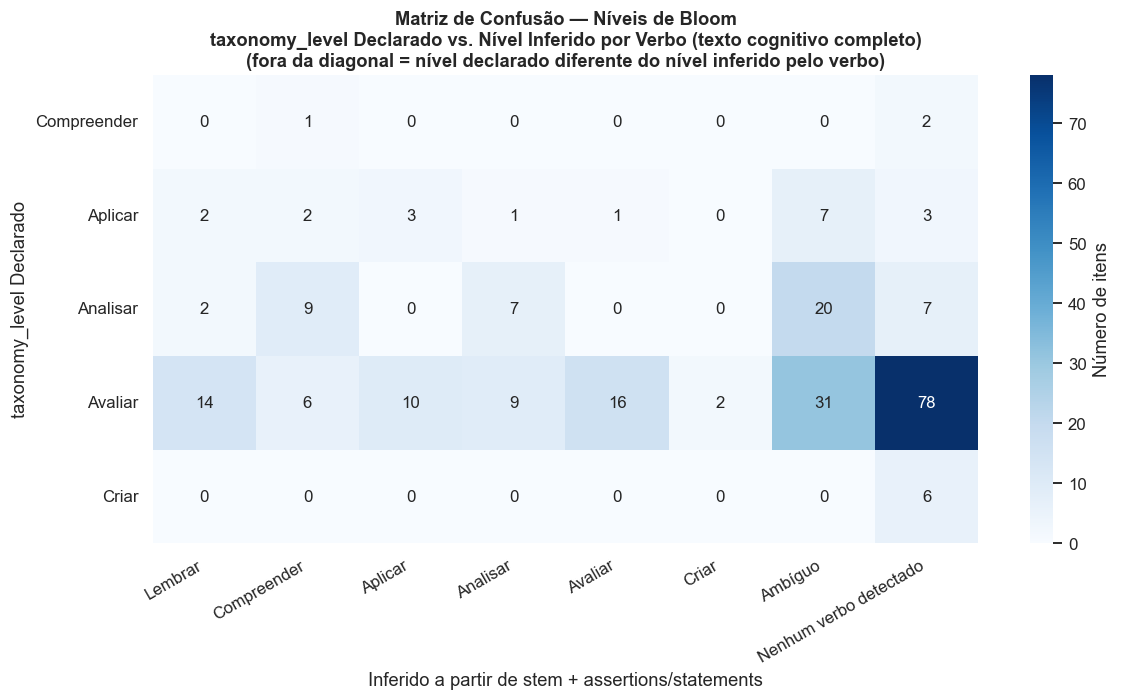

In [18]:
LEVEL_ORDER = ["Lembrar", "Compreender", "Aplicar", "Analisar", "Avaliar", "Criar"]
INFERRED_ORDER = LEVEL_ORDER + ["Ambíguo", "Nenhum verbo detectado"]

def collapse_inferred(x):
    if x.startswith("ambiguous"):
        return "Ambíguo"
    if x == "no_bloom_verb_detected":
        return "Nenhum verbo detectado"
    return x

df["inferred_taxonomy_level_full_display"] = df["inferred_taxonomy_level_full"].apply(collapse_inferred)

confusion = pd.crosstab(
    df["taxonomy_level"], df["inferred_taxonomy_level_full_display"]
)
confusion = confusion.reindex(index=[l for l in LEVEL_ORDER if l in confusion.index],
                                columns=[l for l in INFERRED_ORDER if l in confusion.columns],
                                fill_value=0)

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(confusion, annot=True, fmt="d", cmap=SEQUENTIAL_CMAP, cbar_kws={"label": "Número de itens"}, ax=ax)
ax.set_title("Matriz de Confusão — Níveis de Bloom\n"
              "taxonomy_level Declarado vs. Nível Inferido por Verbo (texto cognitivo completo)\n"
              "(fora da diagonal = nível declarado diferente do nível inferido pelo verbo)")
ax.set_xlabel("Inferido a partir de stem + assertions/statements")
ax.set_ylabel("taxonomy_level Declarado")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_bloom_confusion_matrix.png", bbox_inches="tight")
plt.show()


Items declared at Evaluate/Create level ('Avaliar'/'Criar') delivered as single-best-answer MCQ: 172 / 239 (72.0%)
These are, by R9, structurally invalid regardless of any other quality issue — the format itself is illegal for the declared cognitive level.


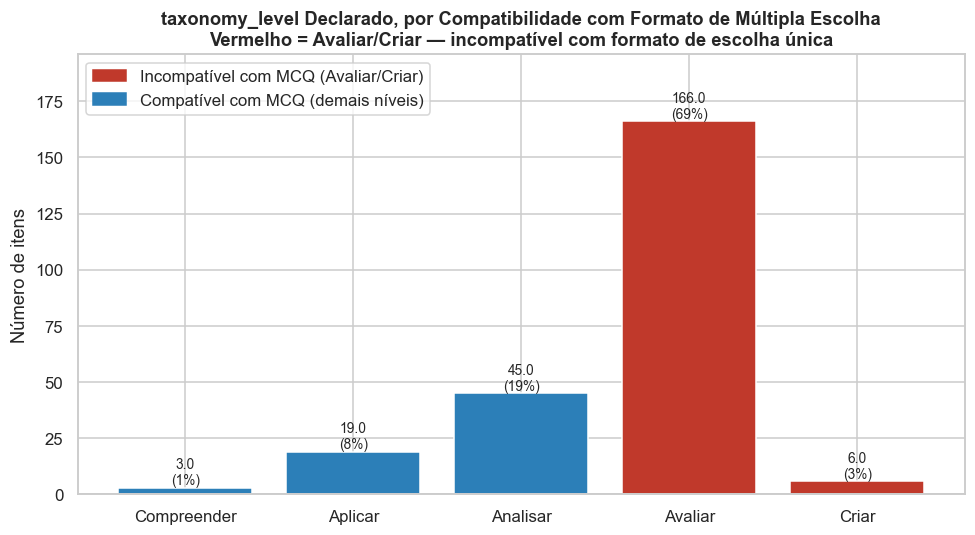

In [19]:
# --- R9: MCQ format is illegal for Evaluate/Create-level content ---
df["violates_r9"] = df["taxonomy_level"].isin(R9_MCQ_ILLEGAL_LEVELS)
n_r9 = df["violates_r9"].sum()
print(f"Items declared at Evaluate/Create level ('Avaliar'/'Criar') delivered as "
      f"single-best-answer MCQ: {n_r9} / {len(df)} ({n_r9/len(df):.1%})")
print("These are, by R9, structurally invalid regardless of any other quality issue "
      "— the format itself is illegal for the declared cognitive level.")

fig, ax = plt.subplots(figsize=(9, 5))
level_counts = df["taxonomy_level"].value_counts().reindex(LEVEL_ORDER).dropna()
colors = [
    "#c0392b" if lvl in R9_MCQ_ILLEGAL_LEVELS else "#2c7fb8"
    for lvl in level_counts.index
]
bars = ax.bar(level_counts.index, level_counts.values, color=colors)
ax.set_title(
    "taxonomy_level Declarado, por Compatibilidade com Formato de Múltipla Escolha\n"
    "Vermelho = Avaliar/Criar — incompatível com formato de escolha única"
)
ax.set_ylabel("Número de itens")
ax.set_ylim(0, level_counts.values.max() * 1.18)
for bar, val in zip(bars, level_counts.values):
    ax.annotate(f"{val}\n({val/len(df):.0%})", (bar.get_x() + bar.get_width()/2, val),
                 ha="center", va="bottom", fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#c0392b", label="Incompatível com MCQ (Avaliar/Criar)"),
                     Patch(color="#2c7fb8", label="Compatível com MCQ (demais níveis)")],
          loc="upper left")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_r9_format_violation.png", bbox_inches="tight")
plt.show()


## 5. Composite Structural Flaw Score (Bonus, No Model Involved)

A simple, transparent rule-count (not a learned score) tallying how many of
the diagnosed structural flaws co-occur in the same item. This is descriptive
bookkeeping over the flags already computed above — useful for prioritizing
which items in the Technical Report to show as illustrative examples.

In [20]:
df["flag_position_bias"] = df["correct_option"] == "A"
df["flag_verbosity_outlier"] = df["is_longest"].fillna(False)
# Uses the full-cognitive-text inference (Section 4.1), not the stem-only one,
# since stem-only conflates "no verb slot in this format" with "generation
# defect" for Assercao-Razao / Multipla Escolha Complexa (see R32 note above).
df["flag_bloom_mismatch"] = single_mask_full & (
    df["inferred_taxonomy_level_full"] != df["taxonomy_level"]
)
df["flag_r9_violation"] = df["violates_r9"]

FLAG_COLS = ["flag_position_bias", "flag_verbosity_outlier",
             "flag_bloom_mismatch", "flag_r9_violation"]
df["structural_flaw_count"] = df[FLAG_COLS].sum(axis=1)

print(df[FLAG_COLS + ["structural_flaw_count"]].sum())
print(f"\nMean flaws per item: {df['structural_flaw_count'].mean():.2f} "
      f"(out of {len(FLAG_COLS)} tracked)")
print(f"Items with ZERO tracked flaws: {(df['structural_flaw_count'] == 0).sum()} "
      f"({(df['structural_flaw_count'] == 0).mean():.1%}) — rejected for reasons "
      f"outside this notebook's four structural checks (e.g. factual error, "
      f"human-only-detectable ambiguity).")


flag_position_bias        193
flag_verbosity_outlier    119
flag_bloom_mismatch        58
flag_r9_violation         172
structural_flaw_count     542
dtype: int64

Mean flaws per item: 2.27 (out of 4 tracked)
Items with ZERO tracked flaws: 4 (1.7%) — rejected for reasons outside this notebook's four structural checks (e.g. factual error, human-only-detectable ambiguity).


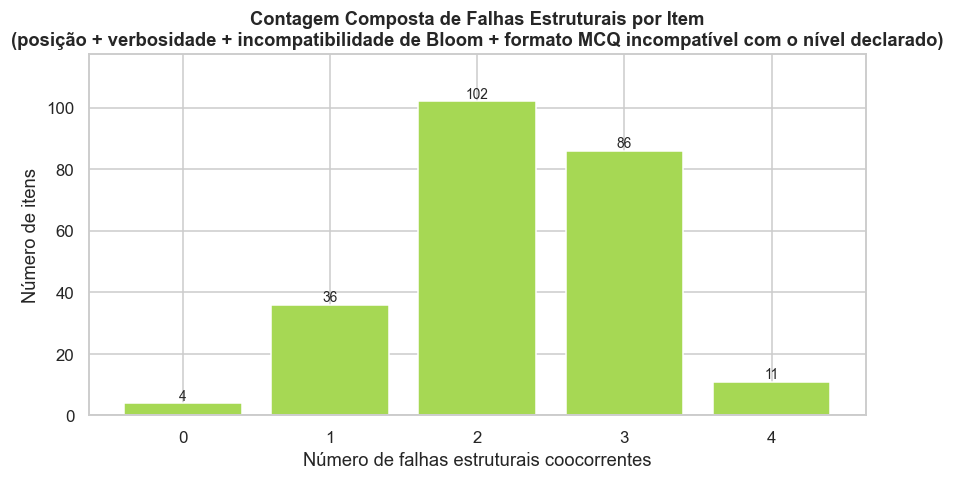

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
counts = df["structural_flaw_count"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=QUALITATIVE_PALETTE[4])
ax.set_title("Contagem Composta de Falhas Estruturais por Item\n"
              "(posição + verbosidade + incompatibilidade de Bloom + formato MCQ incompatível com o nível declarado)")
ax.set_xlabel("Número de falhas estruturais coocorrentes")
ax.set_ylabel("Número de itens")
ax.set_ylim(0, counts.values.max() * 1.15)
for i, v in zip(counts.index.astype(str), counts.values):
    ax.annotate(str(v), (i, v), ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_composite_flaw_count.png", bbox_inches="tight")
plt.show()


In [22]:
summary_cols = [
    "question_id", "discipline", "question_type", "taxonomy_level",
    "inferred_taxonomy_level", "inferred_taxonomy_level_full",
    "correct_option", "correct_len", "distractor_mean_len", "len_diff",
] + FLAG_COLS + ["structural_flaw_count"]

flaw_summary = df[summary_cols].sort_values("structural_flaw_count", ascending=False)
flaw_summary.to_csv(OUTPUT_DIR / "flaw_summary.csv", index=False, encoding="utf-8")
print(f"Saved per-item flaw summary to {OUTPUT_DIR / 'flaw_summary.csv'} "
      f"({len(flaw_summary)} rows).")
flaw_summary.head(10)


Saved per-item flaw summary to output\flaw_summary.csv (239 rows).


,question_id,discipline,question_type,taxonomy_level,inferred_taxonomy_level,inferred_taxonomy_level_full,correct_option,correct_len,distractor_mean_len,len_diff,flag_position_bias,flag_verbosity_outlier,flag_bloom_mismatch,flag_r9_violation,structural_flaw_count
19,63,FISIOTERAPIA DERMATOFUNCIONAL,Afirmação Incompleta,Avaliar,Compreender,Compreender,A,39,30.00,9.00,True,True,True,True,4
30,98,CONEXÃO SEM BARREIRAS EM SAÚDE,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,36,33.00,3.00,True,True,True,True,4
71,251,Morfossintaxe da Língua Inglesa,Afirmação Incompleta,Avaliar,Analisar,Analisar,A,6,5.50,0.50,True,True,True,True,4
107,392,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,17,14.50,2.50,True,True,True,True,4
164,559,Educação de Jovens e Adultos,Afirmação Incompleta,Avaliar,Criar,Criar,A,21,19.00,2.00,True,True,True,True,4
154,528,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,12,4.75,7.25,True,True,True,True,4
132,457,Semântica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,17,13.25,3.75,True,True,True,True,4
179,623,Geografia Econômica,Afirmação Incompleta,Avaliar,Analisar,Analisar,A,14,11.50,2.50,True,True,True,True,4
221,779,Geografia Econômica,Afirmação Incompleta,Avaliar,Lembrar,Lembrar,A,16,13.75,2.25,True,True,True,True,4
215,766,ARTE CONTEMPORÂNEA,Múltipla Escolha Simples,Avaliar,Lembrar,Lembrar,A,54,46.50,7.50,True,True,True,True,4


## 6. Summary of Findings — for the WAPLA Technical Report

The cell below prints an auto-generated summary sourced directly from the
statistics computed above (no hardcoded numbers), so it stays accurate if the
notebook is re-run against a dataset revision.

In [23]:
summary = f'''
STRUCTURAL DIAGNOSIS SUMMARY - {len(df)} Rejected AI-Generated Questions
================================================================

1) VERBOSITY BIAS (R16, R22)
   - Mean (correct - mean distractor) length: {mean_diff:+.2f} words
     [95% bootstrap CI: {ci_lo:+.2f}, {ci_hi:+.2f}] (Wilcoxon p={wilcoxon_p:.3g})
   - correct_option is the LONGEST option in {pct_longest:.1f}% of items
     (chance level: 20.0%)

2) POSITION BIAS (R21, R16)
   - P(correct_option == "A") = {p_a:.1%} [95% CI: {p_a_lo:.1%}, {p_a_hi:.1%}]
     vs. chance level of 20.0%
   - Chi-square goodness-of-fit vs. uniform: chi2={chi2:.1f}, p={chi2_p:.3g}

3) BLOOM'S TAXONOMY MISMATCH (R6-R11)
   - Using full cognitive text (stem + assertions/statements, Section 4.1):
     {n_none_full} items ({n_none_full/len(df):.1%}) contain NO canonical
     Bloom-level verb anywhere in the item -- violates R10's fixed-template
     requirement
   - Among items with an unambiguous verb match, declared/inferred level
     mismatch rate: {1 - match_rate_full:.1%}
   - (Diagnostic note: stem-only extraction found {n_none} items ({n_none/len(df):.1%})
     with no verb, but 100% of that figure for Assercao-Razao/Multipla Escolha
     Complexa was a format artifact -- generic boilerplate stems -- not a
     generation defect; see Section 4.1)
   - {n_r9} items ({n_r9/len(df):.1%}) are declared Evaluate/Create-level
     content delivered in a single-best-answer MCQ format -- structurally
     illegal under R9 regardless of any other quality dimension

4) COMPOSITE
   - Mean tracked structural flaws per item: {df["structural_flaw_count"].mean():.2f} / 4
   - Items with zero tracked flaws (rejected for other reasons):
     {(df["structural_flaw_count"] == 0).sum()} ({(df["structural_flaw_count"] == 0).mean():.1%})

All figures saved to: {OUTPUT_DIR.resolve()}
'''
print(summary)

with open(OUTPUT_DIR / "eda_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)



STRUCTURAL DIAGNOSIS SUMMARY - 239 Rejected AI-Generated Questions

1) VERBOSITY BIAS (R16, R22)
   - Mean (correct - mean distractor) length: +2.29 words
     [95% bootstrap CI: +1.74, +2.88] (Wilcoxon p=3.64e-16)
   - correct_option is the LONGEST option in 49.8% of items
     (chance level: 20.0%)

2) POSITION BIAS (R21, R16)
   - P(correct_option == "A") = 80.8% [95% CI: 75.7%, 85.8%]
     vs. chance level of 20.0%
   - Chi-square goodness-of-fit vs. uniform: chi2=558.1, p=1.82e-119

3) BLOOM'S TAXONOMY MISMATCH (R6-R11)
   - Using full cognitive text (stem + assertions/statements, Section 4.1):
     96 items (40.2%) contain NO canonical
     Bloom-level verb anywhere in the item -- violates R10's fixed-template
     requirement
   - Among items with an unambiguous verb match, declared/inferred level
     mismatch rate: 68.2%
   - (Diagnostic note: stem-only extraction found 139 items (58.2%)
     with no verb, but 100% of that figure for Assercao-Razao/Multipla Escolha
     Compl

## Next Steps (Not Implemented Here)

This notebook is **strictly EDA** — no model was trained or fine-tuned. The
findings above are structural evidence for the WAPLA Technical Report and
should inform, but do not yet implement, fixes to the Generator/Judge
pipeline in `spec.md`:

- **§4.2.1** (Bias-Mitigated Judge Protocol) — the position/verbosity checks
  above are exactly the generation-side analogues of the judge-side controls
  already specified there.
- **§4.4** (IRT Calibration Layer) — R9-illegal items (Evaluate/Create in MCQ
  format) should be routed to the open-response generation path instead of
  regenerated as MCQ.
- **Rubric/verb templates (R10)** — the Bloom verb bank used here should be
  promoted from an EDA diagnostic into the actual generation-prompt contract.
